Colunas numéricas encontradas: ['Unnamed: 0', 'Nota', 'N_Avaliações', 'Desconto', 'Preço', 'Nota_MinMax', 'N_Avaliações_MinMax', 'Desconto_MinMax', 'Preço_MinMax', 'Marca_Cod', 'Material_Cod', 'Temporada_Cod', 'Qtd_Vendidos_Cod', 'Marca_Freq', 'Material_Freq']


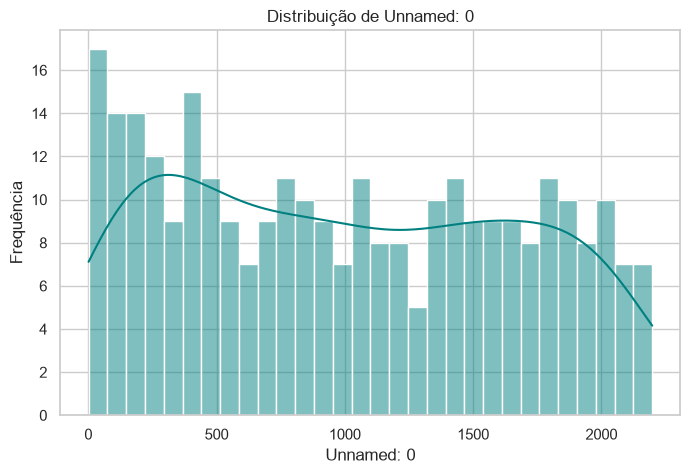

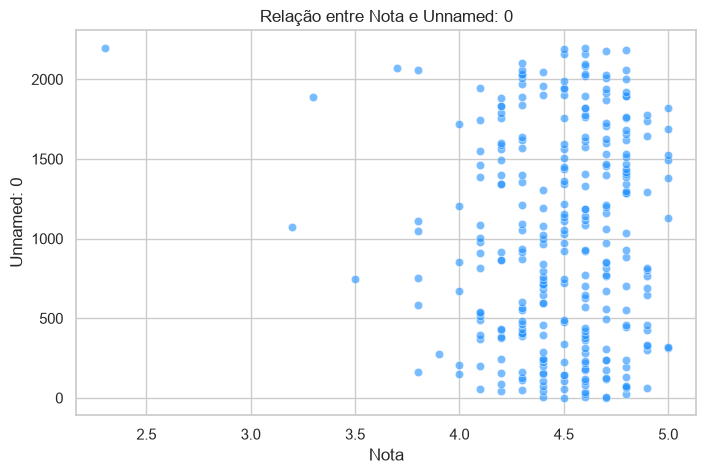

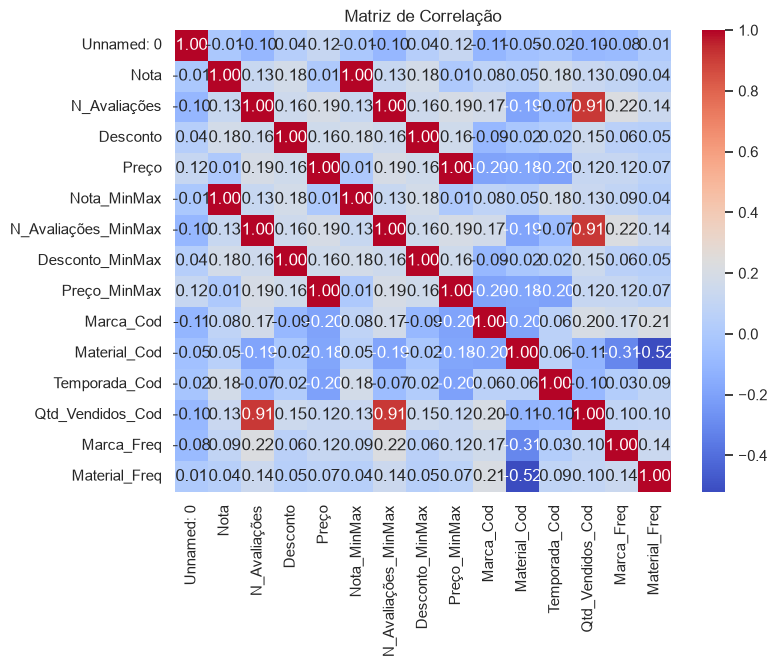

C:\Users\Paulo\AppData\Local\Temp\ipykernel_21816\1087476094.py:54: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  colunas_texto = df.select_dtypes(include=['object']).columns.tolist()
C:\Users\Paulo\AppData\Local\Temp\ipykernel_21816\1087476094.py:61: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_dados.index, y=top_dados.values, palette='viridis')


Utilizando a coluna para o gráfico de barras: Título


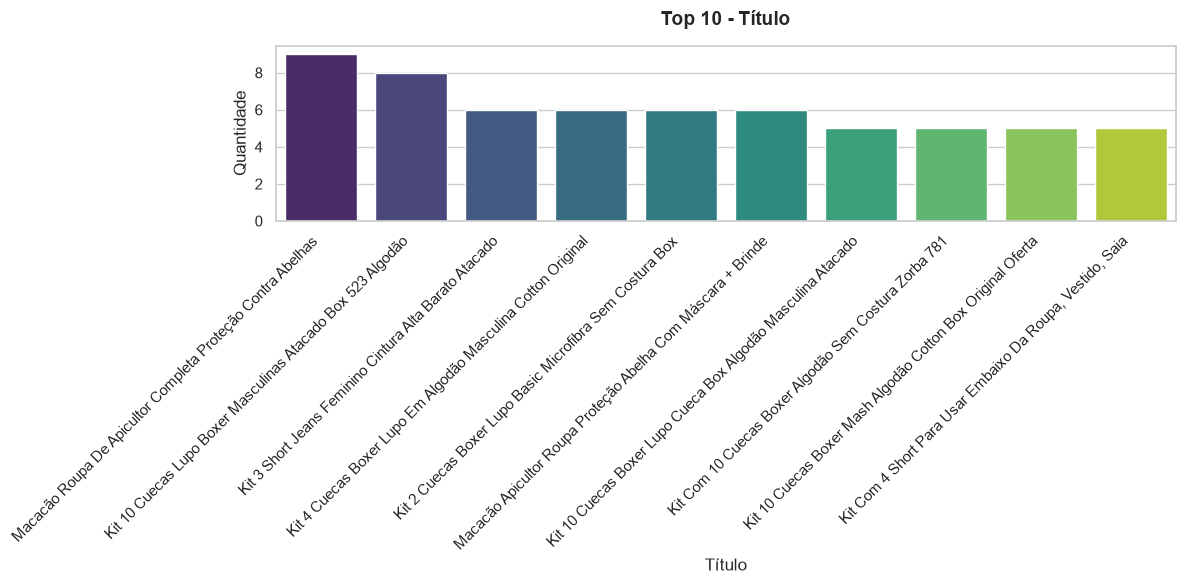

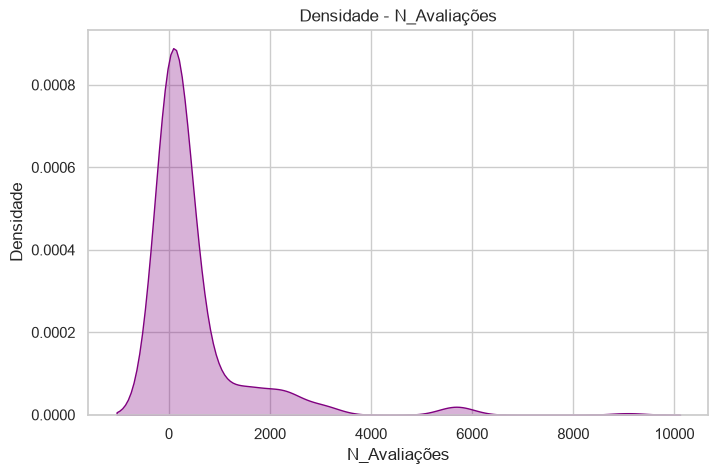

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configuração visual limpa
sns.set_theme(style="whitegrid")

# Carrega os dados
df = pd.read_csv('ecommerce_estatistica.csv')
colunas_numericas = df.select_dtypes(include=['float64', 'int64']).columns.tolist()

col_x = colunas_numericas[1] if len(colunas_numericas) > 1 else colunas_numericas[0]
col_y = colunas_numericas[0]

# ---------------------------------------------------------
# 1. Histograma com salvamento automático
# ---------------------------------------------------------
plt.figure(figsize=(8, 5))
sns.histplot(df[col_y], kde=True, color='teal', bins=30)
plt.title(f'Distribuição de {col_y}')
plt.xlabel(col_y)
plt.ylabel('Frequência')

# Salva o gráfico antes de mostrar
plt.savefig('grafico_1_histograma.png', dpi=300, bbox_inches='tight')
plt.show()

# ---------------------------------------------------------
# 2. Gráfico de Dispersão com salvamento automático
# ---------------------------------------------------------
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x=col_x, y=col_y, color='dodgerblue', alpha=0.6)
plt.title(f'Relação entre {col_x} e {col_y}')
plt.xlabel(col_x)
plt.ylabel(col_y)

plt.savefig('grafico_2_dispersao.png', dpi=300, bbox_inches='tight')
plt.show()

# ---------------------------------------------------------
# 3. Mapa de Calor (Correlação)
# ---------------------------------------------------------
plt.figure(figsize=(8, 6))
sns.heatmap(df[colunas_numericas].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Matriz de Correlação')
plt.show()

# ---------------------------------------------------------
# 4. Gráfico de Barras (Top Categorias/Produtos)
# ---------------------------------------------------------
plt.figure(figsize=(12, 6))

# Tenta encontrar automaticamente uma coluna de texto (object) no DataFrame
colunas_texto = df.select_dtypes(include=['object']).columns.tolist()
coluna_alvo = 'Titulo' if 'Titulo' in df.columns else ('titulo' in df.columns and 'titulo' or (colunas_texto[0] if len(colunas_texto) > 0 else df.columns[0]))

print(f"Utilizando a coluna para o gráfico de barras: {coluna_alvo}")

top_dados = df[coluna_alvo].value_counts().head(10)

sns.barplot(x=top_dados.index, y=top_dados.values, palette='viridis')
plt.title(f'Top 10 - {coluna_alvo}', fontsize=14, fontweight='bold', pad=15)
plt.xlabel(coluna_alvo, fontsize=12)
plt.ylabel('Quantidade', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 5. Gráfico de Densidade (Notas / Variável Numérica)
# ---------------------------------------------------------
plt.figure(figsize=(8, 5))
# Utiliza a terceira coluna numérica se houver, senão usa a primeira
col_densidade = colunas_numericas[2] if len(colunas_numericas) > 2 else col_y
sns.kdeplot(df[col_densidade], fill=True, color='purple', alpha=0.3)
plt.title(f'Densidade - {col_densidade}')
plt.xlabel(col_densidade)
plt.ylabel('Densidade')
plt.show()